# Предсказание выработки электроэнергии на парогазовой электростанции (CCPP)

**Задача:** регрессия — по погодным условиям и вакууму предсказать чистую выработку PE (МВт).
**Датасет:** UCI Combined Cycle Power Plant, 9568 почасовых записей, 4 признака.

План:
1. Загрузка и очистка данных, EDA
2. Разбиение train/test **до** масштабирования (без утечки данных)
3. Нейронная сеть (Keras) с EarlyStopping и ReduceLROnPlateau
4. Оценка: метрики, график «предсказание vs факт», анализ остатков
5. Сравнение с базовыми моделями (линейная регрессия, Random Forest, XGBoost) и упрощённой НС
6. Кросс-валидация (5 фолдов) и выводы

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Фиксируем seed, чтобы результаты воспроизводились при каждом запуске
SEED = 42
tf.keras.utils.set_random_seed(SEED)

I0000 00:00:1795090985.849966     172 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795090986.991679     172 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Загрузка и очистка данных

In [2]:
url = "https://risk-engineering.org/static/data/CCPP.csv"
df = pd.read_csv(url)

print("Размер датасета:", df.shape)
print("Пропуски:", df.isna().sum().sum())
print("Дубликаты:", df.duplicated().sum())

# Удаляем дубликаты, чтобы одинаковые строки не попали одновременно в train и test
df = df.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", df.shape)
display(df.describe().round(2))

Размер датасета: (9568, 5)
Пропуски: 0
Дубликаты: 41
После удаления дубликатов: (9527, 5)


,AT,V,AP,RH,PE
count,9527.00,9527.00,9527.00,9527.00,9527.00
mean,19.66,54.29,1013.24,73.33,454.34
std,7.44,12.69,5.94,14.61,17.04
min,1.81,25.36,992.89,25.56,420.26
25%,13.53,41.74,1009.08,63.38,439.75
50%,20.35,52.08,1012.92,75.00,451.52
75%,25.71,66.51,1017.20,84.85,468.36
max,37.11,81.56,1033.30,100.16,495.76


## 2. Разведочный анализ (EDA)
Признаки: **AT** — температура (°C), **V** — вакуум (см рт.ст.), **AP** — давление (мбар), **RH** — влажность (%).
Цель: **PE** — выработка (МВт).

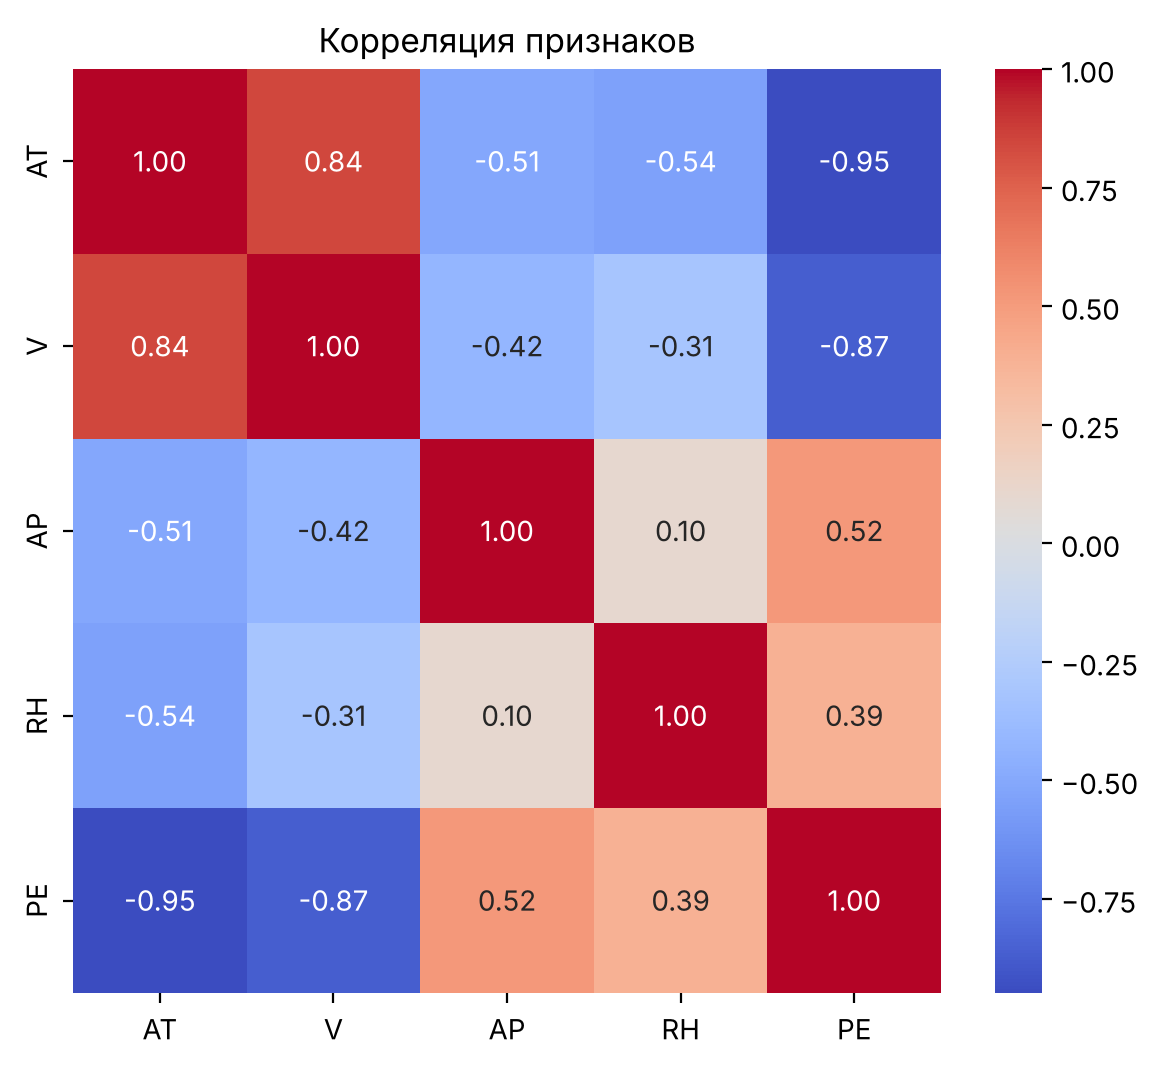

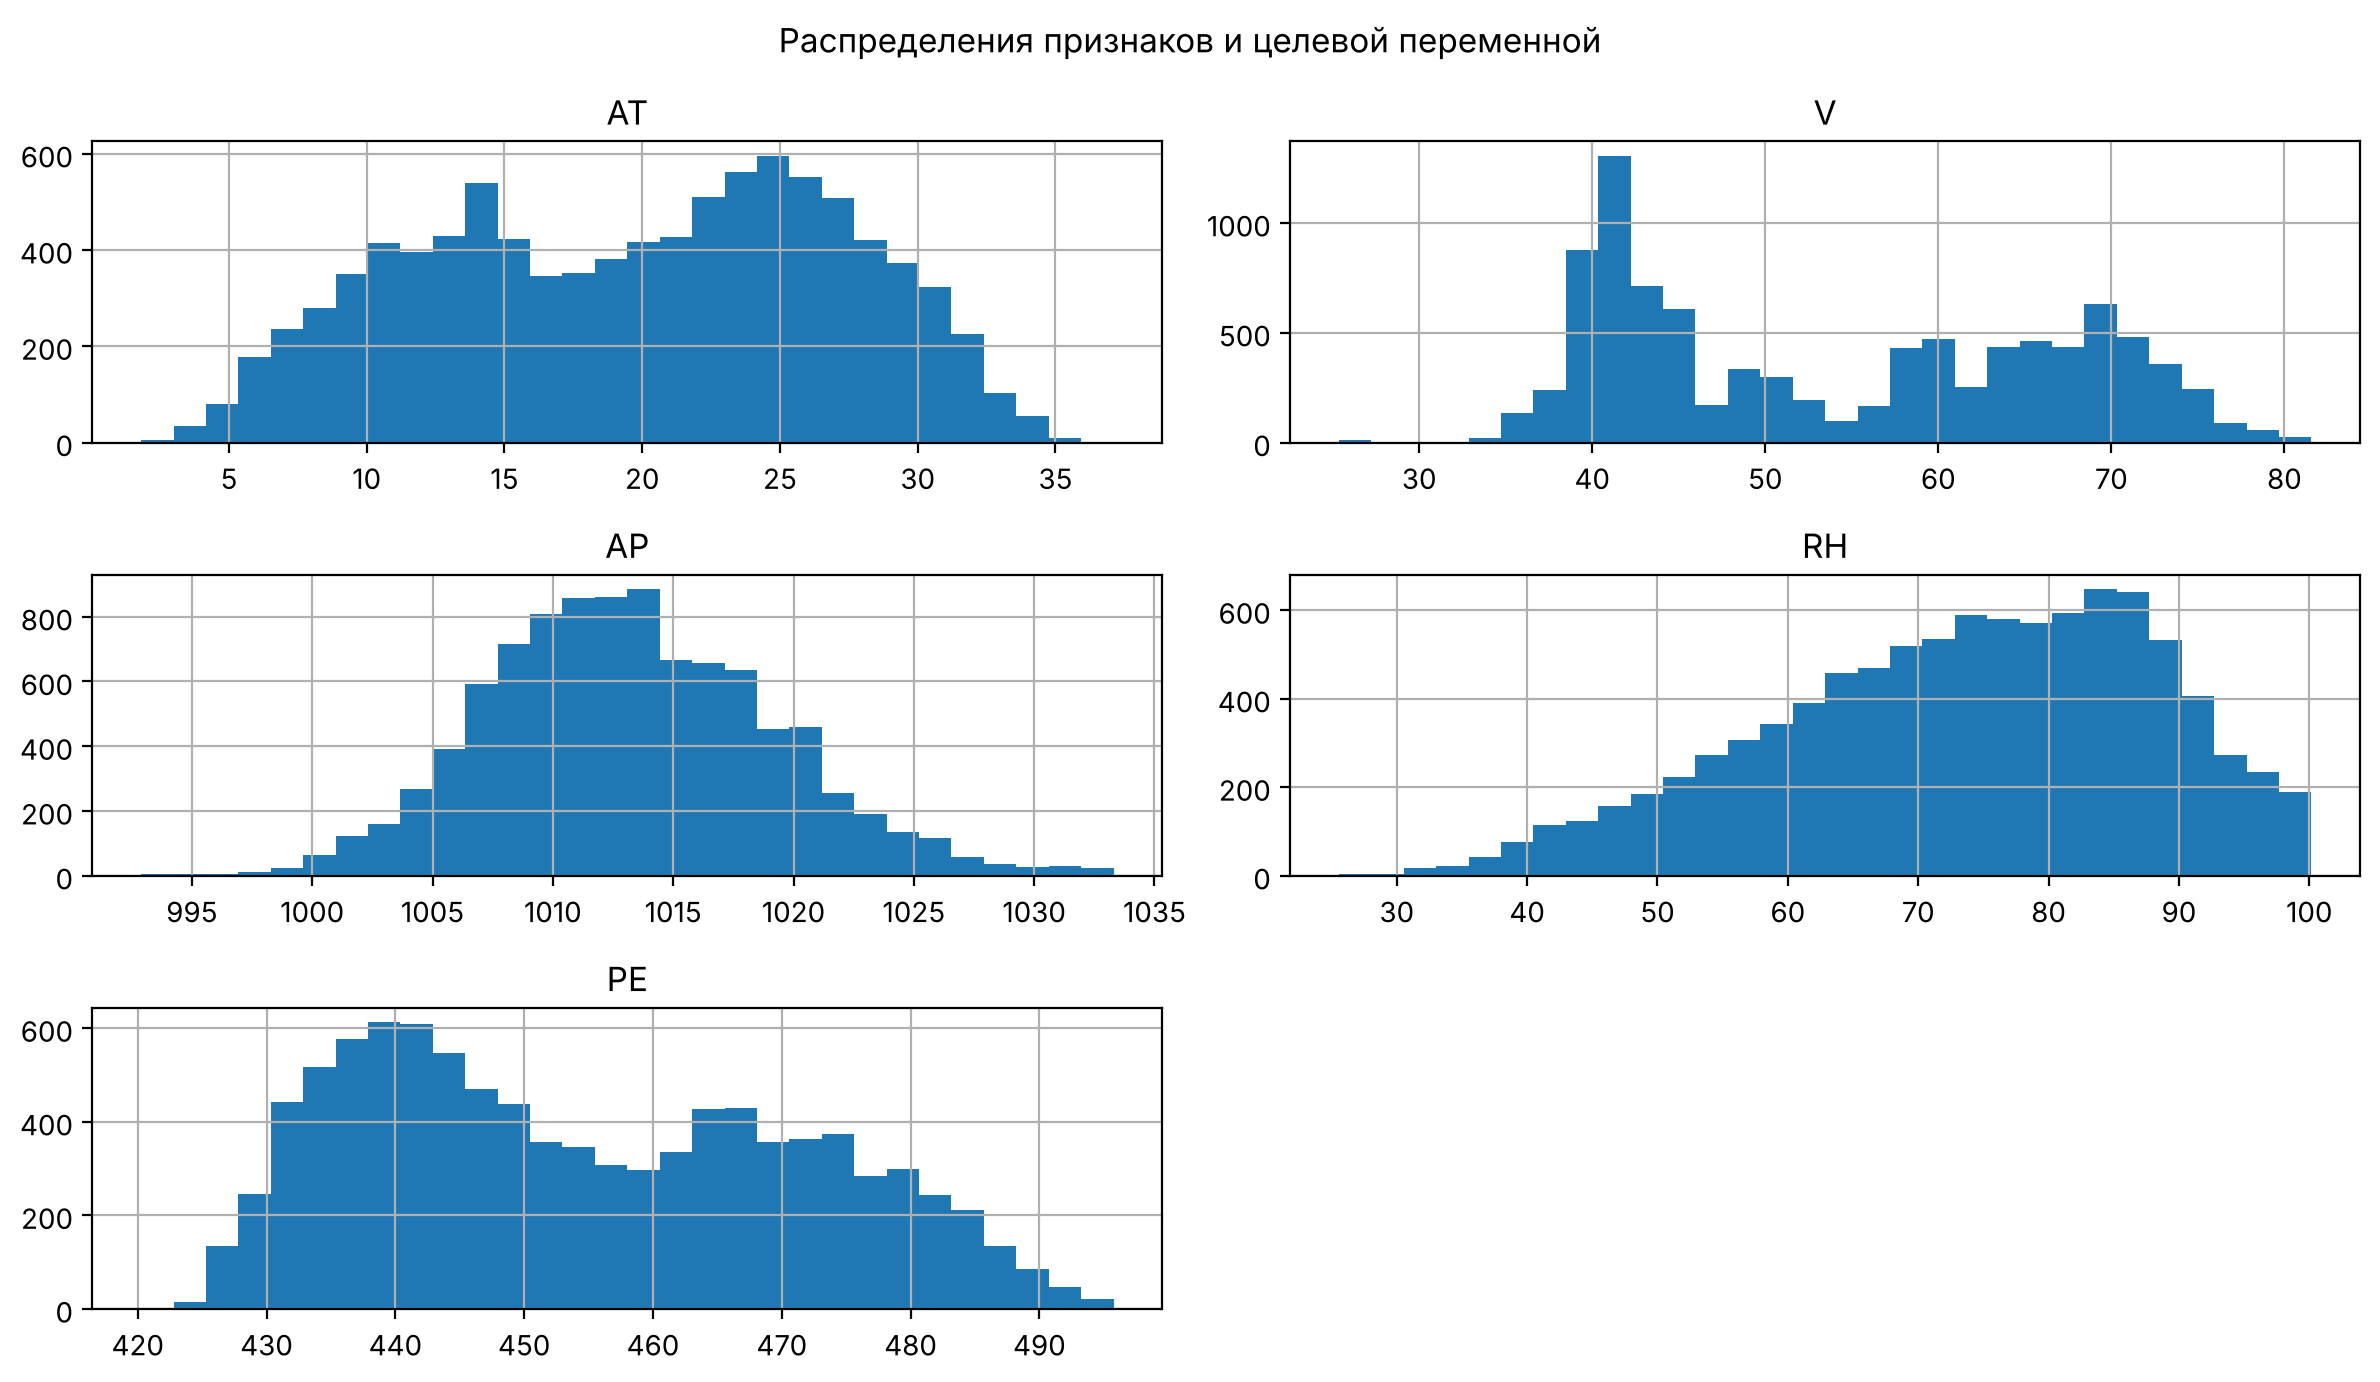

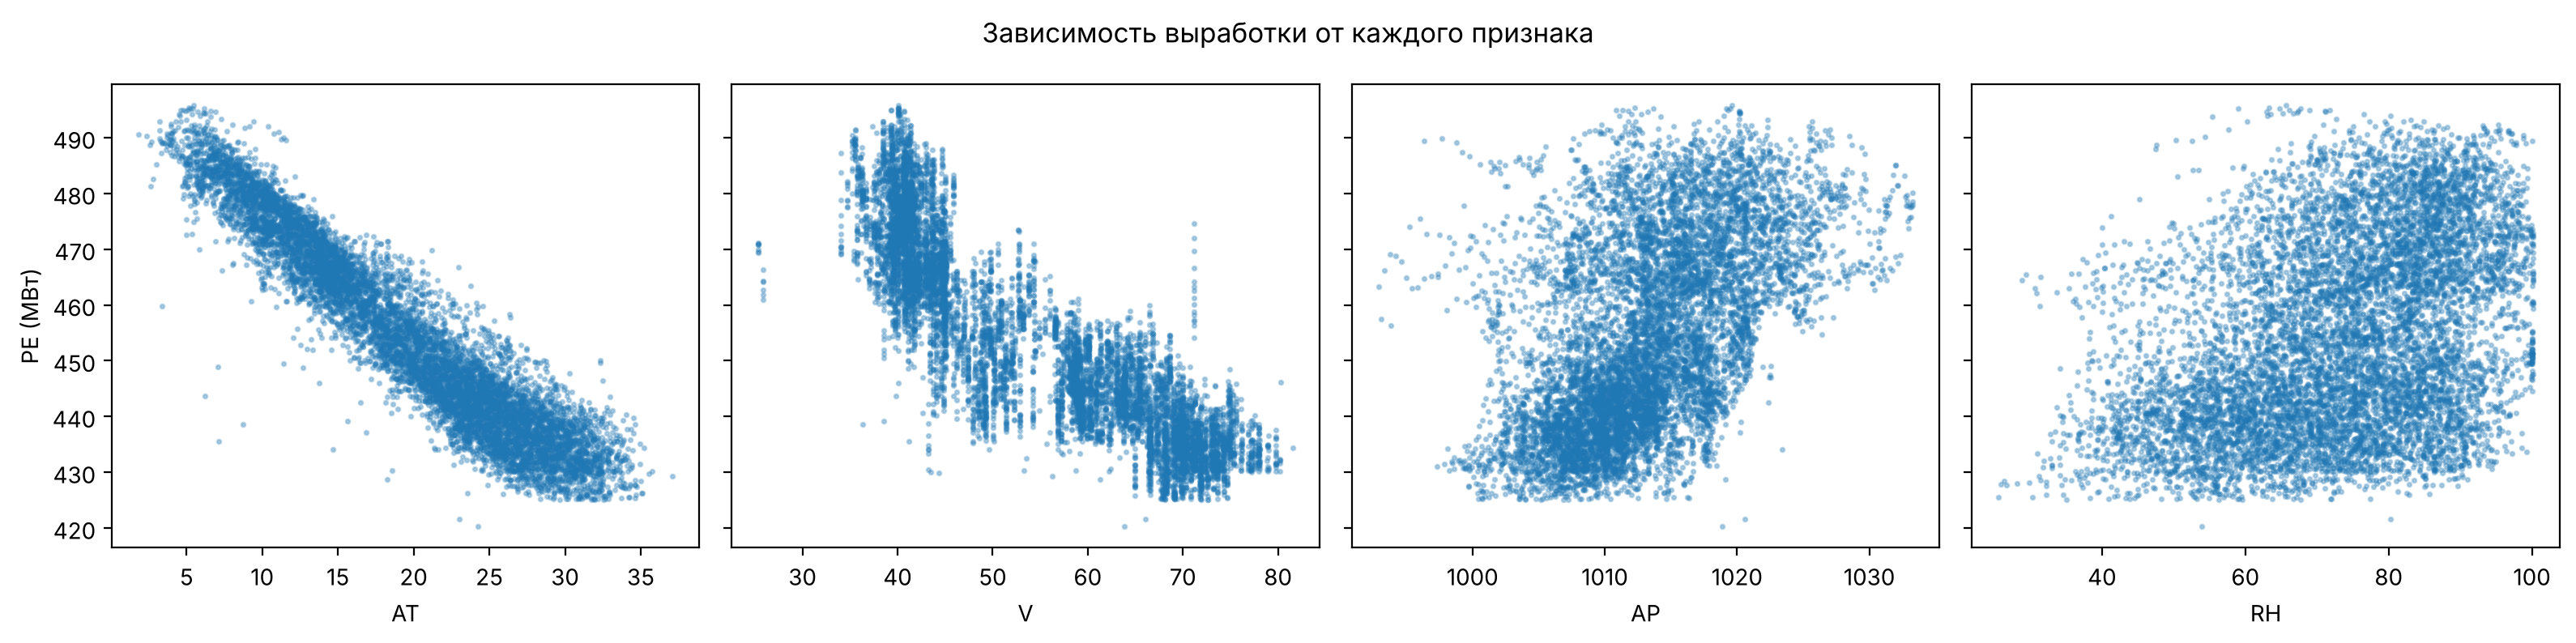

In [3]:
plt.figure(figsize=(7, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляция признаков')
plt.show()

df.hist(bins=30, figsize=(12, 7))
plt.suptitle('Распределения признаков и целевой переменной')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ['AT', 'V', 'AP', 'RH']):
    ax.scatter(df[col], df['PE'], s=3, alpha=0.3)
    ax.set_xlabel(col)
axes[0].set_ylabel('PE (МВт)')
plt.suptitle('Зависимость выработки от каждого признака')
plt.tight_layout()
plt.show()

**Наблюдение:** температура AT и вакуум V сильно и отрицательно связаны с выработкой —
чем жарче, тем ниже мощность. Давление и влажность влияют слабее.

## 3. Разбиение и масштабирование
Сначала делим данные, потом обучаем `StandardScaler` **только на train**.
Иначе модель заранее «видит» статистику тестовой выборки — это утечка данных (data leakage).

In [4]:
X = df[['AT', 'V', 'AP', 'RH']].values
y = df['PE'].values.reshape(-1, 1)

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

scaler_X = StandardScaler().fit(X_train_raw)
scaler_y = StandardScaler().fit(y_train_raw)

X_train = scaler_X.transform(X_train_raw)
X_test  = scaler_X.transform(X_test_raw)
y_train = scaler_y.transform(y_train_raw)
y_test  = scaler_y.transform(y_test_raw)

print(f"Train: {X_train.shape[0]} примеров, Test: {X_test.shape[0]} примеров")

Train: 7621 примеров, Test: 1906 примеров


## 4. Нейронная сеть
Архитектура: 4 → 256 → 128 → 64 → 32 → 1, ReLU, BatchNorm, Dropout на первых двух слоях.

In [5]:
def build_big_model():
    model = Sequential([
        Input(shape=(4,)),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),

        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.1),

        Dense(64, activation='relu'),
        BatchNormalization(),

        Dense(32, activation='relu'),
        BatchNormalization(),

        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
    return model

model = build_big_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,465 (181.50 KB)

 Trainable params: 45,505 (177.75 KB)

 Non-trainable params: 960 (3.75 KB)

Обучение: максимум 1000 эпох — остановку решает **EarlyStopping**.
**ReduceLROnPlateau** уменьшает шаг обучения, когда val_loss перестаёт улучшаться.

In [6]:
def make_callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=40, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15, min_lr=1e-5, verbose=0),
    ]

history = model.fit(
    X_train, y_train,
    epochs=1000,
    batch_size=64,
    validation_split=0.2,
    callbacks=make_callbacks(),
    verbose=0
)
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f"Обучение остановлено на эпохе {len(history.history['loss'])}, лучшая эпоха: {best_epoch}")

Epoch 187: early stopping


Restoring model weights from the end of the best epoch: 147.


Обучение остановлено на эпохе 187, лучшая эпоха: 147


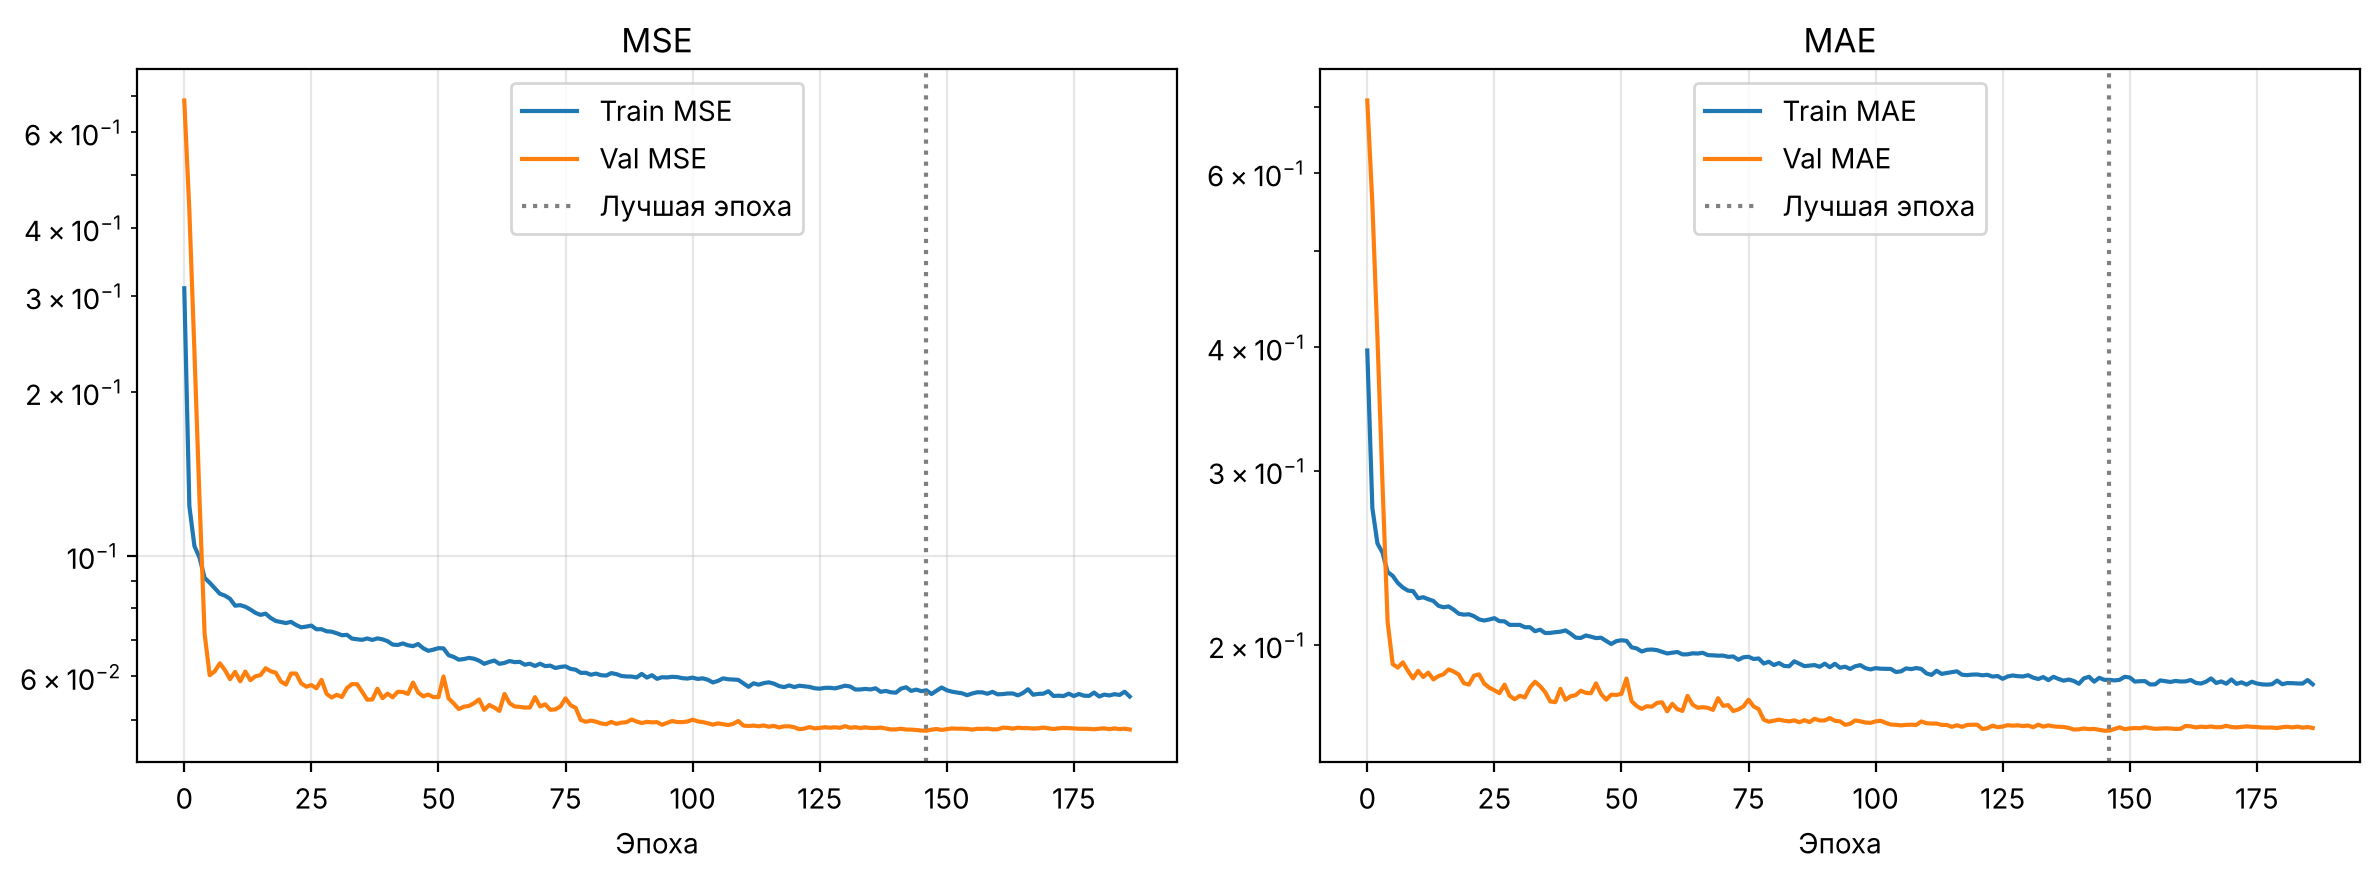

In [7]:
plt.figure(figsize=(12, 4.5))
for i, (key, name) in enumerate([('loss', 'MSE'), ('mae', 'MAE')], 1):
    plt.subplot(1, 2, i)
    plt.plot(history.history[key], label=f'Train {name}')
    plt.plot(history.history['val_' + key], label=f'Val {name}')
    plt.axvline(best_epoch - 1, color='gray', ls=':', label='Лучшая эпоха')
    plt.title(name); plt.xlabel('Эпоха'); plt.yscale('log')
    plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*Почему val_loss ниже train_loss?* Dropout и BatchNorm работают в режиме обучения только на train —
модель «мешает» сама себе. На валидации они отключены, поэтому ошибка там ниже. Это нормально.

## 5. Оценка на тестовой выборке

In [8]:
def metrics(y_true, y_pred):
    return {
        'RMSE, МВт': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE, МВт': mean_absolute_error(y_true, y_pred),
        'R²': r2_score(y_true, y_pred),
    }

y_true = y_test_raw.ravel()
y_pred_nn = scaler_y.inverse_transform(model.predict(X_test, verbose=0)).ravel()

m = metrics(y_true, y_pred_nn)
for k, v in m.items():
    print(f"{k:10s} = {v:.4f}")
print(f"Средняя мощность: {y_true.mean():.2f} МВт")
print(f"MAE  относительно средней мощности: {m['MAE, МВт']  / y_true.mean() * 100:.2f}%")
print(f"RMSE относительно средней мощности: {m['RMSE, МВт'] / y_true.mean() * 100:.2f}%")

RMSE, МВт  = 3.9221
MAE, МВт   = 2.9108
R²         = 0.9477
Средняя мощность: 454.33 МВт
MAE  относительно средней мощности: 0.64%
RMSE относительно средней мощности: 0.86%


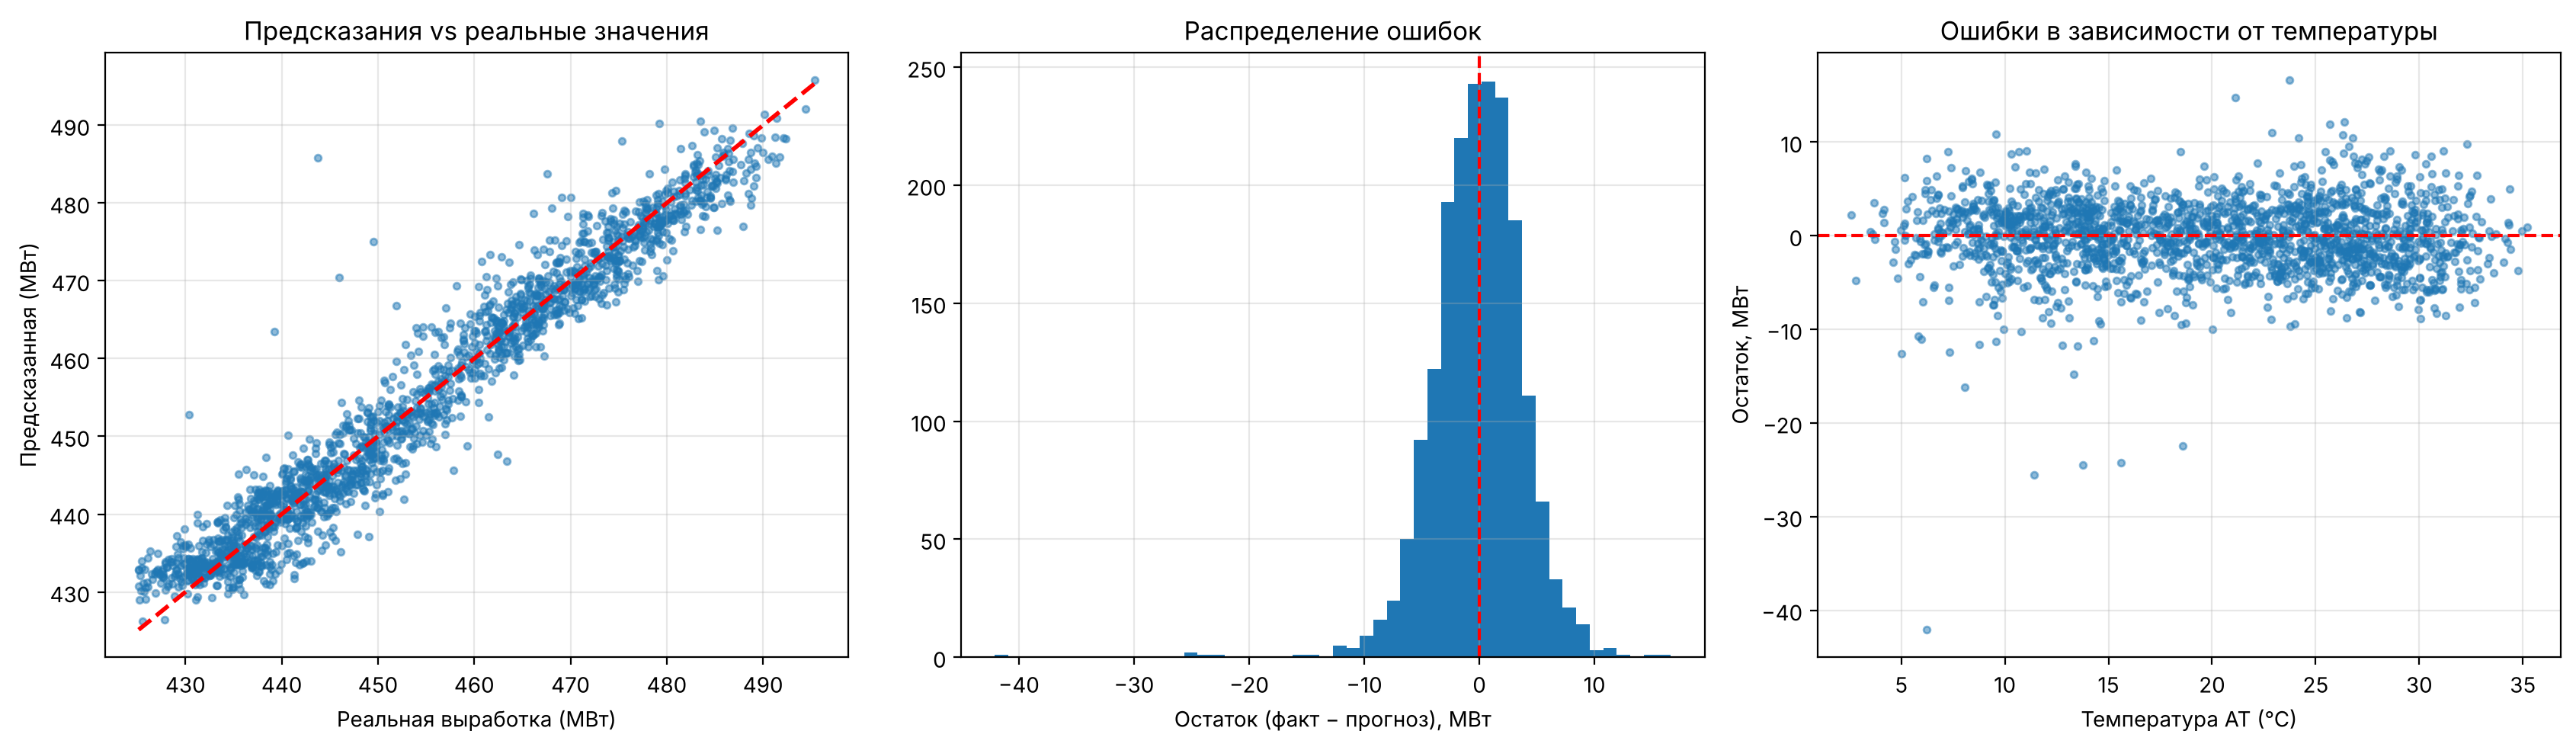

Доля прогнозов с ошибкой меньше 5 МВт: 84.7%


In [9]:
residuals = y_true - y_pred_nn
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(y_true, y_pred_nn, alpha=0.5, s=10)
lims = [y_true.min(), y_true.max()]
axes[0].plot(lims, lims, 'r--', lw=2)
axes[0].set_xlabel('Реальная выработка (МВт)'); axes[0].set_ylabel('Предсказанная (МВт)')
axes[0].set_title('Предсказания vs реальные значения')

axes[1].hist(residuals, bins=50)
axes[1].axvline(0, color='r', ls='--')
axes[1].set_xlabel('Остаток (факт − прогноз), МВт'); axes[1].set_title('Распределение ошибок')

axes[2].scatter(X_test_raw[:, 0], residuals, alpha=0.5, s=10)
axes[2].axhline(0, color='r', ls='--')
axes[2].set_xlabel('Температура AT (°C)'); axes[2].set_ylabel('Остаток, МВт')
axes[2].set_title('Ошибки в зависимости от температуры')

for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Доля прогнозов с ошибкой меньше 5 МВт: {(np.abs(residuals) < 5).mean() * 100:.1f}%")

## 6. Сравнение с другими моделями
Чтобы понять, насколько хорош результат, сравним НС с:
- **линейной регрессией** — простейший baseline;
- **Random Forest** и **XGBoost** — сильные модели для табличных данных;
- **упрощённой НС** (64 → 32, без BatchNorm и Dropout) — проверяем, нужна ли большая архитектура.

In [10]:
def build_small_model():
    model = Sequential([
        Input(shape=(4,)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=0.002), loss='mse', metrics=['mae'])
    return model

tf.keras.utils.set_random_seed(SEED)
small_model = build_small_model()
small_model.fit(X_train, y_train, epochs=1000, batch_size=64, validation_split=0.2,
                callbacks=make_callbacks(), verbose=0)
y_pred_small = scaler_y.inverse_transform(small_model.predict(X_test, verbose=0)).ravel()

sk_models = {
    'Линейная регрессия': make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=SEED),
    'XGBoost': XGBRegressor(n_estimators=1500, learning_rate=0.03, max_depth=6,
                            subsample=0.8, colsample_bytree=0.8, random_state=SEED),
}

results = {}
for name, mdl in sk_models.items():
    mdl.fit(X_train_raw, y_train_raw.ravel())
    results[name] = metrics(y_true, mdl.predict(X_test_raw))

results[f'НС большая ({model.count_params():,} парам.)'] = metrics(y_true, y_pred_nn)
results[f'НС малая ({small_model.count_params():,} парам.)'] = metrics(y_true, y_pred_small)

results_df = pd.DataFrame(results).T.sort_values('RMSE, МВт')
display(results_df.round(4))

Epoch 282: early stopping


Restoring model weights from the end of the best epoch: 242.


,"RMSE, МВт","MAE, МВт",R²
XGBoost,3.2218,2.2194,0.9647
Random Forest,3.4309,2.4073,0.9599
"НС большая (46,465 парам.)",3.9221,2.9108,0.9477
"НС малая (2,433 парам.)",3.9646,2.9500,0.9465
Линейная регрессия,4.5875,3.6215,0.9284


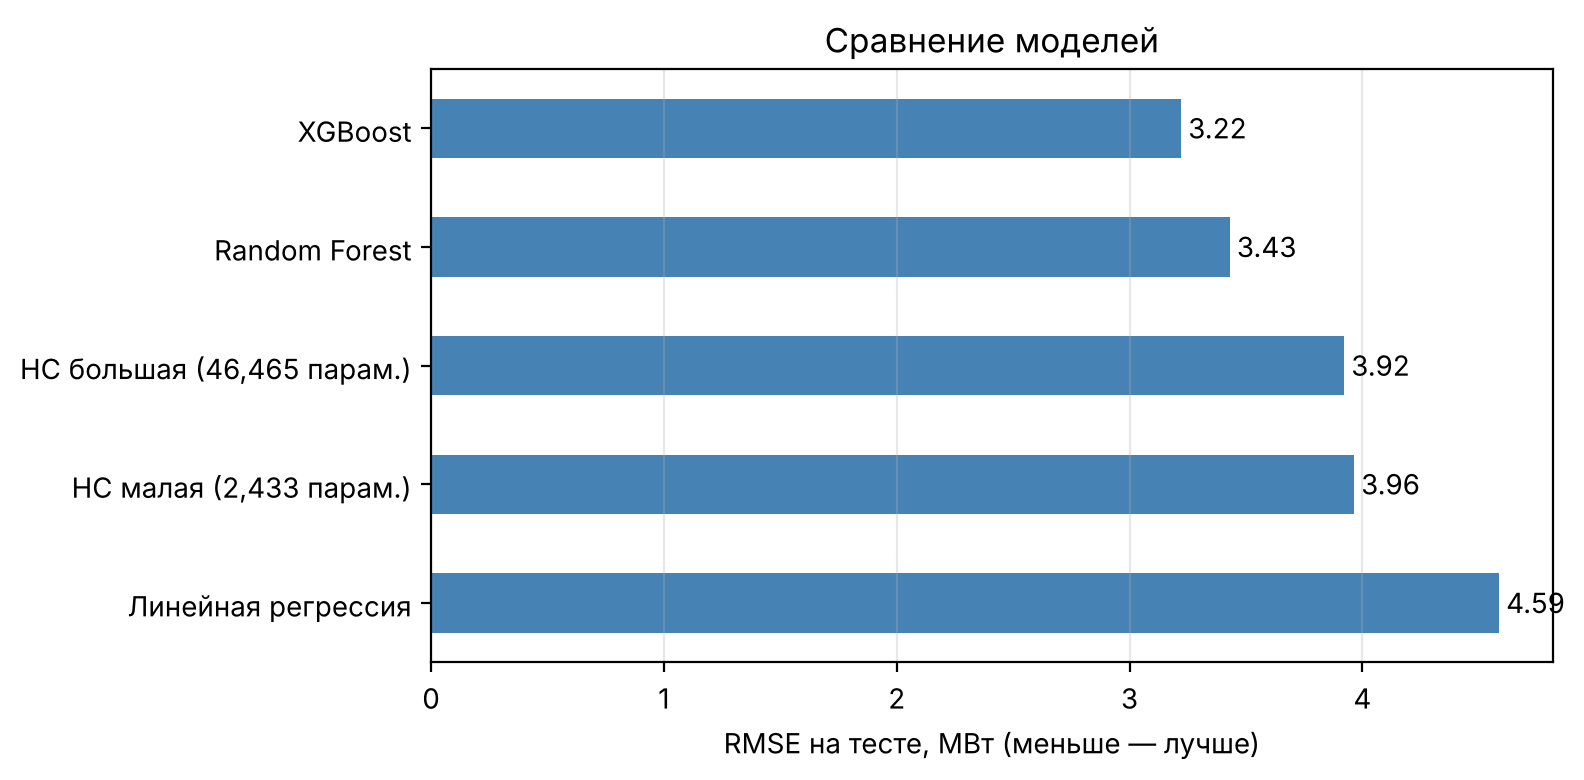

In [11]:
ax = results_df['RMSE, МВт'].sort_values().plot.barh(figsize=(8, 4), color='steelblue')
ax.invert_yaxis()
ax.set_xlabel('RMSE на тесте, МВт (меньше — лучше)')
ax.set_title('Сравнение моделей')
for i, v in enumerate(results_df['RMSE, МВт'].sort_values()):
    ax.text(v + 0.03, i, f'{v:.2f}', va='center')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Кросс-валидация (5 фолдов)
Одно разбиение train/test может оказаться «удачным» или «неудачным».
Кросс-валидация даёт среднюю ошибку и её разброс.

In [12]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = {}

for name, mdl in sk_models.items():
    scores = -cross_val_score(mdl, X, y.ravel(), cv=kf, scoring='neg_root_mean_squared_error')
    cv_rows[name] = scores

# Кросс-валидация для НС (большая модель: используем ту же функцию построения)
for nn_name, builder in [('НС большая', build_big_model), ('НС малая', build_small_model)]:
    scores = []
    for tr_idx, te_idx in kf.split(X):
        sx = StandardScaler().fit(X[tr_idx]); sy = StandardScaler().fit(y[tr_idx])
        tf.keras.utils.set_random_seed(SEED)
        mdl = builder()
        mdl.fit(sx.transform(X[tr_idx]), sy.transform(y[tr_idx]), epochs=1000, batch_size=64,
                validation_split=0.2, callbacks=make_callbacks(), verbose=0)
        pred = sy.inverse_transform(mdl.predict(sx.transform(X[te_idx]), verbose=0)).ravel()
        scores.append(np.sqrt(mean_squared_error(y[te_idx].ravel(), pred)))
    cv_rows[nn_name] = np.array(scores)

cv_df = pd.DataFrame({
    'RMSE среднее, МВт': {k: v.mean() for k, v in cv_rows.items()},
    'Разброс (std)': {k: v.std() for k, v in cv_rows.items()},
}).sort_values('RMSE среднее, МВт')
display(cv_df.round(3))

Epoch 231: early stopping


Restoring model weights from the end of the best epoch: 191.


Epoch 289: early stopping


Restoring model weights from the end of the best epoch: 249.


Epoch 167: early stopping


Restoring model weights from the end of the best epoch: 127.


... (10 outputs left out)

Restoring model weights from the end of the best epoch: 1000.


Epoch 262: early stopping


Restoring model weights from the end of the best epoch: 222.


,"RMSE среднее, МВт",Разброс (std)
XGBoost,3.074,0.109
Random Forest,3.325,0.096
НС большая,3.815,0.060
НС малая,3.836,0.082
Линейная регрессия,4.560,0.063


## 8. Выводы
- Нейронная сеть объясняет около 95% дисперсии выработки и заметно точнее линейной регрессии —
  значит, она улавливает нелинейные зависимости.
- Упрощённая сеть даёт сопоставимую точность при гораздо меньшем числе параметров:
  для 4 признаков большая архитектура с BatchNorm и Dropout избыточна.
- На табличных данных такого размера градиентный бустинг (XGBoost) точнее нейронной сети.
  Это известный результат: НС сильнее на изображениях, тексте и очень больших данных.
- Главный фактор — температура воздуха: с её ростом выработка падает.

**Ограничения:** данные одной станции за 2006–2011 гг.; модель прогнозирует выработку
по текущим показаниям, а не на часы вперёд (для этого нужен прогноз погоды и вакуума).